# Testing drift bursts against controlled null models

Drift and volatility increase as time approaches a chosen burst location:

$$
\mu_t=\frac{a(t)}{|t-\tau|^{\alpha}},\qquad
\sigma_t=\frac{b(t)}{|t-\tau|^{\beta}},\qquad \tau=\frac12.
$$

Here, $t$ is normalized time; $\tau=\tfrac12$ is the burst location; $\mu_t$ is drift; $\sigma_t$ is volatility. $a(t)$ and $b(t)$ set their signed and positive scales; $\alpha$ and $\beta$ control how sharply they rise near $\tau.$

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("02_synthetic_financial_environments");


## Regularized Burst Profile

A positive distance floor prevents the drift and volatility profiles from becoming infinite at the burst location:

$$
d_{\delta}(t)=\max\{|t-\tfrac12|,\delta\},\qquad
\mu_t=\frac{a(t)}{d_{\delta}(t)^{\alpha}},\qquad
\sigma_t=\frac{b(t)}{d_{\delta}(t)^{\beta}},\qquad t\neq\tfrac12.
$$

Here, $d_\delta(t)$ is the floored distance to $\tfrac12$; $\delta>0$ is the smallest allowed distance; $t$ is normalized time. $\mu_t$ and $\sigma_t$ are drift and volatility; $a(t),b(t)$ are scale functions; $\alpha,\beta$ are burst exponents.

In [2]:
observation_count = 501
time = collect(range(0., 1.; length=observation_count))
midpoint = observation_count÷2+1
a_before, a_after, b_before, b_after = 0.025, -0.018, 0.12, 0.18
alpha, beta, filter_width = 0.35, 0.22, 0.06
drift, volatility = RiskLabAI.Data.drift_volatility_burst(observation_count, a_before, a_after, b_before, b_after, alpha, beta; explosion_filter_width=filter_width)
drift_burst_parameters = DataFrame("Quantity"=>["Observations", "Pre-burst drift scale", "Post-burst drift scale", "Pre-burst volatility scale", "Post-burst volatility scale", "Drift exponent", "Volatility exponent", "Regularization width"], "Value"=>[observation_count, a_before, a_after, b_before, b_after, alpha, beta, filter_width])
save_table(drift_burst_parameters, paths, "drift_burst_parameters"; caption="Parameters for the regularized drift and volatility burst.", label="tab:drift-burst-parameters")


Row,Quantity,Value
,String,Float64
1,Observations,501.0
2,Pre-burst drift scale,0.025
3,Post-burst drift scale,-0.018
4,Pre-burst volatility scale,0.12
5,Post-burst volatility scale,0.18
6,Drift exponent,0.35
7,Volatility exponent,0.22
8,Regularization width,0.06


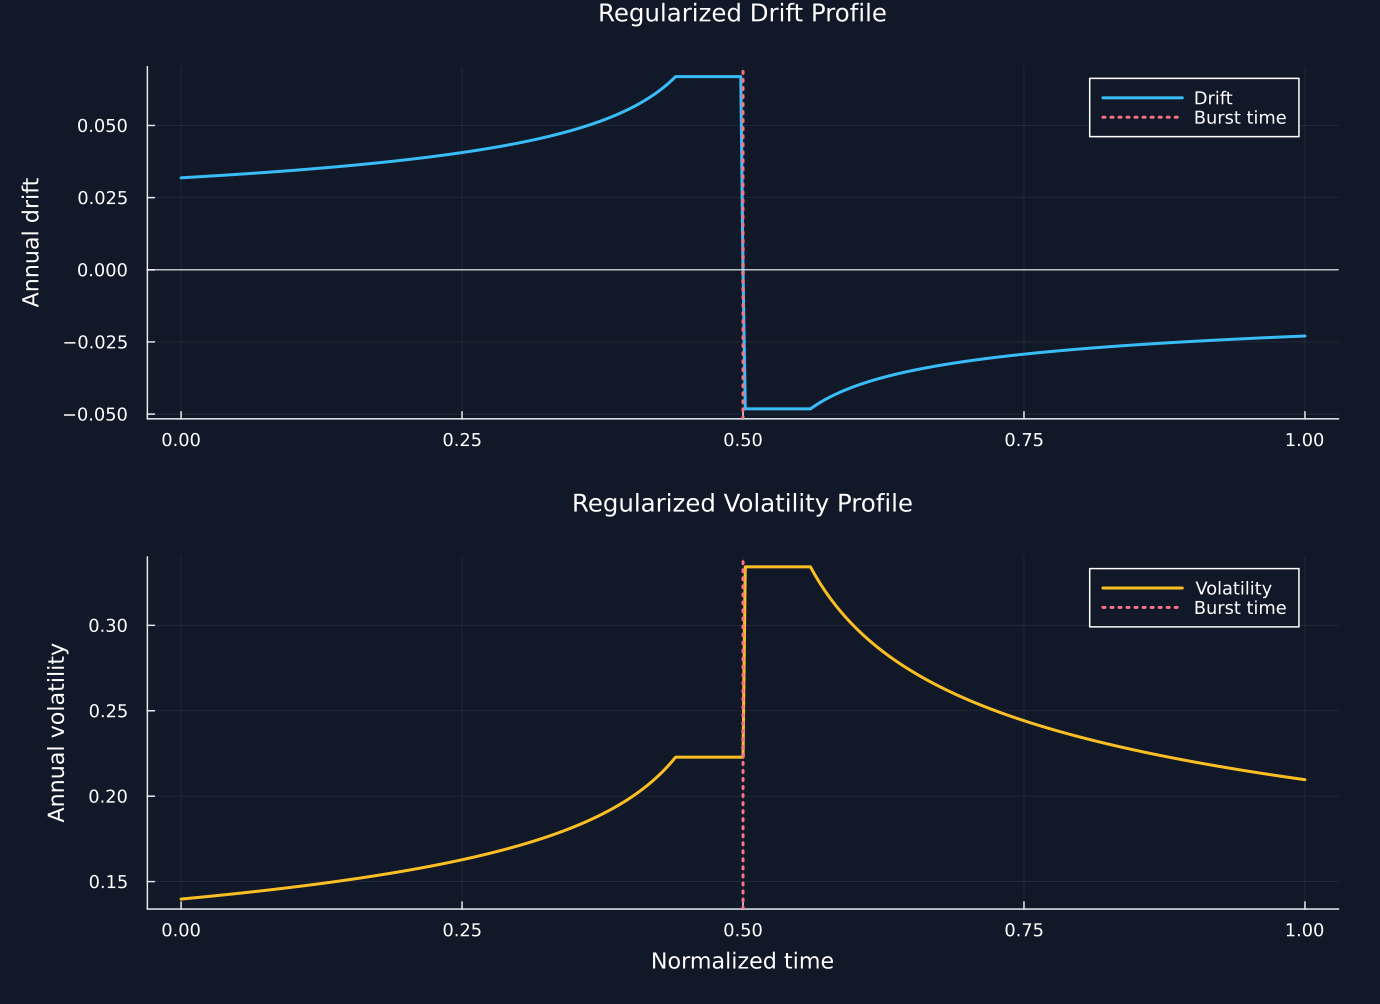

In [3]:
drift_panel = plot(time, drift; color=palette.cyan, label="Drift", ylabel="Annual drift", title="Regularized Drift Profile")
hline!(drift_panel, [0.]; color=palette.text, linewidth=0.8, label="")
vline!(drift_panel, [0.5]; color=palette.rose, linestyle=:dot, label="Burst time")
volatility_panel = plot(time, volatility; color=palette.amber, label="Volatility", xlabel="Normalized time", ylabel="Annual volatility", title="Regularized Volatility Profile")
vline!(volatility_panel, [0.5]; color=palette.rose, linestyle=:dot, label="Burst time")
figure = plot(drift_panel, volatility_panel; layout=(2, 1), link=:x, size=(920, 670))
save_data(DataFrame("Normalized time"=>time, "Drift"=>drift, "Volatility"=>volatility), paths, "drift_burst_profiles")
save_figure(figure, paths, "drift_burst_profiles")


## Comparing paired null and alternative paths

The two return paths share the same shocks, so their difference isolates the time-varying drift and volatility:

$$
R_t^{(0)}=\mu_0\Delta+\sigma_0\sqrt{\Delta}\,Z_t,\qquad
R_t^{(1)}=\mu_t\Delta+\sigma_t\sqrt{\Delta}\,Z_t,
\qquad Z_t\overset{\mathrm{iid}}{\sim}\mathcal N(0,1).
$$

Here, $R_t^{(0)}$ is the constant-parameter return; $R_t^{(1)}$ is the burst return; $\mu_0,\sigma_0$ are fixed drift and volatility. $\mu_t,\sigma_t$ vary through time; $\Delta$ is the time step; $Z_t$ is an independent standard-normal shock; iid means independent and identically distributed.

In [4]:
time_step = 1/252
innovations = randn(Xoshiro(20260929), observation_count)
null_drift, null_volatility = 0., median(volatility)
null_returns = null_drift*time_step.+null_volatility*sqrt(time_step).*innovations
alternative_returns = drift.*time_step.+volatility.*sqrt(time_step).*innovations
null_prices = 100 .* exp.(cumsum(null_returns))
alternative_prices = 100 .* exp.(cumsum(alternative_returns))
maximum_drawdown(prices) = minimum(prices./accumulate(max, prices).-1)
controlled_alternative_summary = DataFrame("Environment"=>["Null", "Burst alternative"], "Terminal price"=>[last(null_prices), last(alternative_prices)], "Annualized mean return"=>[mean(null_returns)/time_step, mean(alternative_returns)/time_step], "Annualized volatility"=>[std(null_returns)/sqrt(time_step), std(alternative_returns)/sqrt(time_step)], "Maximum drawdown"=>[maximum_drawdown(null_prices), maximum_drawdown(alternative_prices)], "One-percent return quantile"=>[quantile(null_returns, 0.01), quantile(alternative_returns, 0.01)])
save_table(controlled_alternative_summary, paths, "controlled_alternative_summary"; caption="Paired null and burst-alternative outcomes under common innovations.", label="tab:controlled-alternative-summary")
save_data(DataFrame("Normalized time"=>time, "Innovation"=>innovations, "Null return"=>null_returns, "Alternative return"=>alternative_returns, "Null price"=>null_prices, "Alternative price"=>alternative_prices), paths, "paired_null_alternative");


Row,Environment,Terminal price,Annualized mean return,Annualized volatility,Maximum drawdown,One-percent return quantile
,String,Float64,Float64,Float64,Float64,Float64
1,Null,131.213,0.136641,0.215442,-0.188392,-0.0309038
2,Burst alternative,129.523,0.13012,0.223885,-0.23092,-0.0330536


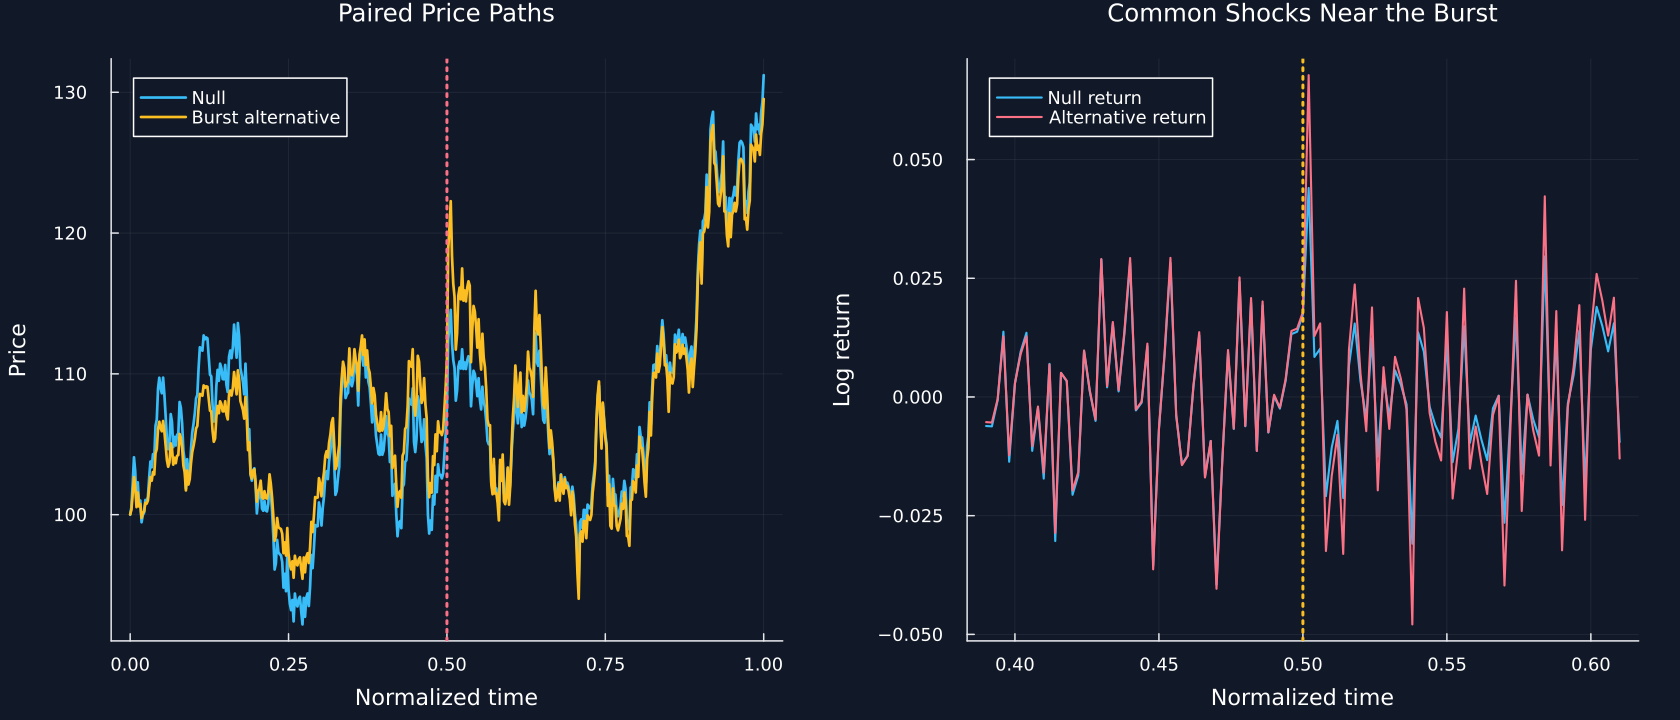

In [5]:
local_window = midpoint-55:midpoint+55
price_panel = plot(time, null_prices; color=palette.cyan, linewidth=1.8, label="Null", xlabel="Normalized time", ylabel="Price", title="Paired Price Paths")
plot!(price_panel, time, alternative_prices; color=palette.amber, linewidth=1.8, label="Burst alternative")
vline!(price_panel, [0.5]; color=palette.rose, linestyle=:dot, label="")
return_panel = plot(time[local_window], null_returns[local_window]; color=palette.cyan, linewidth=1.4, label="Null return", xlabel="Normalized time", ylabel="Log return", title="Common Shocks Near the Burst")
plot!(return_panel, time[local_window], alternative_returns[local_window]; color=palette.rose, linewidth=1.4, label="Alternative return")
vline!(return_panel, [0.5]; color=palette.amber, linestyle=:dot, label="")
figure = plot(price_panel, return_panel; layout=(1, 2), size=(1120, 480))
save_figure(figure, paths, "paired_null_alternative")


## Tests

In [6]:
repeated_innovations = randn(Xoshiro(20260929), observation_count)
expected_pre_drift, expected_post_drift = a_before/filter_width^alpha, a_after/filter_width^alpha
expected_pre_volatility, expected_post_volatility = b_before/filter_width^beta, b_after/filter_width^beta
recovered_null_innovations = (null_returns.-null_drift*time_step)./(null_volatility*sqrt(time_step))
recovered_alternative_innovations = (alternative_returns.-drift.*time_step)./(volatility.*sqrt(time_step))
@assert size(drift) == size(volatility) == (observation_count,)
@assert time[midpoint] ≈ 0.5
@assert drift[midpoint] == 0
@assert volatility[midpoint] == volatility[midpoint-1]
@assert drift[midpoint-1] ≈ expected_pre_drift
@assert drift[midpoint+1] ≈ expected_post_drift
@assert volatility[midpoint-1] ≈ expected_pre_volatility
@assert volatility[midpoint+1] ≈ expected_post_volatility
@assert innovations == repeated_innovations
@assert recovered_null_innovations ≈ innovations
@assert recovered_alternative_innovations ≈ innovations
@assert all(isfinite, null_prices) && all(null_prices .> 0)
@assert all(isfinite, alternative_prices) && all(alternative_prices .> 0)
@assert null_returns != alternative_returns
@assert nrow(controlled_alternative_summary) == 2
